# Homework 2 — Question 1

%pip install numpy pandas pyarrow scipy scikit-learn matplotlib torch

## (a) Output link functions

Write the two outputs of the neural network as $g(x)=(g_1(x),g_2(x))$. Use

$$f_\mu(x)=g_1(x), \qquad f_\sigma(x)=\log(1+e^{g_2(x)})+\epsilon.$$

The identity function allows an unrestricted mean, and softplus makes the standard deviation positive. I use $\epsilon=10^{-4}$ for numerical stability.


## (b) Training loss

Assume $Y_i\mid X_i=x_i\sim N(\mu_i,\sigma_i^2)$, where $\mu_i=f_\mu(x_i)$ and $\sigma_i=f_\sigma(x_i)$. Minimize the average Gaussian negative log-likelihood:

$$L(\theta)=\frac1n\sum_{i=1}^n\left[\frac12\log(2\pi)+\log\sigma_i+\frac{(y_i-\mu_i)^2}{2\sigma_i^2}\right].$$

The constant $\frac12\log(2\pi)$ can be omitted during optimization, but I include it in the code and the reported NLL values. The $\log\sigma_i$ term penalizes increasing the predicted uncertainty without limit.


## (c) Data, baselines, and MLP

The dataset has 523,554 observations, seven features, and no missing values. I use `trip_duration` as the target and all seven other columns as inputs. The supplied features are already standardized, so I do not standardize them again. I retain all observations and predict duration in minutes without transforming the target.

Using random seed 42, I split the data into 366,487 training observations, 78,533 validation observations, and 78,534 test observations (approximately 70% / 15% / 15%). This random split evaluates performance on held-out trips from the supplied dataset;

I compare two baselines with the MLP:

1. **Constant baseline:** the training-set mean and standard deviation for every trip.
2. **Linear regression baseline:** an ordinary linear regression for the mean, with a constant standard deviation estimated from the training residuals.

The MLP has architecture **7 → 64 → 64 → 2**, with ReLU in both hidden layers. Its two outputs define the mean and the standard deviation as in part (a). I minimize Gaussian NLL with Adam, learning rate 0.001, and batch size 1,024. Training runs for at most 100 epochs and stops after eight consecutive epochs without an improvement in validation NLL. I restore the parameters with the lowest validation NLL. The test set is not used for model selection.

Training ran for **74 epochs**. The best parameters were from **epoch 66**, with validation NLL **2.636399**.


### Imports

In [6]:
import copy
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.stats import norm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, brier_score_loss, mean_squared_error
from sklearn.model_selection import train_test_split
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(2)



### Load and split the data

In [7]:
data = pd.read_parquet("taxi_trips.parquet")
x = data.drop(columns="trip_duration").to_numpy(dtype="float32")
y = data["trip_duration"].to_numpy(dtype="float32")

assert np.isfinite(x).all() and np.isfinite(y).all()

# The supplied features are already standardized.
x_train, x_temp, y_train, y_temp = train_test_split(
    x, y, test_size=0.30, random_state=42
)
x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp, test_size=0.50, random_state=42
)

print("Data shape:", data.shape)
print("Features:", list(data.drop(columns="trip_duration").columns))
print("Missing values:", int(data.isna().sum().sum()))
print("Train / validation / test:", len(y_train), len(y_val), len(y_test))



Data shape: (523554, 8)
Features: ['pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'min_of_day', 'day_of_week', 'day_of_year']
Missing values: 0
Train / validation / test: 366487 78533 78534


### Baselines

In [8]:
# Constant Gaussian: training mean and training standard deviation.
mean = float(np.mean(y_train))
sd = float(np.std(y_train))

# Linear Gaussian: linear mean and a constant residual standard deviation.
linear = LinearRegression()
linear.fit(x_train, y_train)
sd_linear = float(np.sqrt(np.mean((y_train - linear.predict(x_train)) ** 2)))
print("Constant baseline: mean =", round(mean, 4), "; sd =", round(sd, 4))
print("Linear baseline: residual sd =", round(sd_linear, 4))



Constant baseline: mean = 10.4163 ; sd = 7.7553
Linear baseline: residual sd = 7.5444


### MLP and Gaussian negative log-likelihood

In [9]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(7, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 2),
        )

    def forward(self, x):
        out = self.net(x)
        mean = out[:, 0]
        sd = F.softplus(out[:, 1]) + 1e-4
        return mean, sd


def loss_fn(y, mean, sd):
    loss = 0.5 * np.log(2 * np.pi) + torch.log(sd)
    loss = loss + 0.5 * ((y - mean) / sd) ** 2
    return loss.mean()


train = TensorDataset(torch.tensor(x_train), torch.tensor(y_train))
loader = DataLoader(train, batch_size=1024, shuffle=True)
x_val_t = torch.tensor(x_val)
y_val_t = torch.tensor(y_val)

model = MLP()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)



### Train with early stopping

In [10]:
best_loss = float("inf")
best_epoch = 0
wait = 0
train_losses = []
val_losses = []

for epoch in range(100):
    model.train()
    total = 0.0

    for xb, yb in loader:
        optimizer.zero_grad()
        mean_b, sd_b = model(xb)
        loss = loss_fn(yb, mean_b, sd_b)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb)

    model.eval()
    with torch.no_grad():
        mean_val, sd_val = model(x_val_t)
        val_loss = loss_fn(y_val_t, mean_val, sd_val).item()

    train_loss = total / len(train)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_loss:
        best_loss = val_loss
        best_epoch = epoch + 1
        best_model = copy.deepcopy(model.state_dict())
        wait = 0
    else:
        wait += 1

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1}: train NLL = {train_loss:.4f}, val NLL = {val_loss:.4f}")

    if wait >= 8:
        break

model.load_state_dict(best_model)
model.eval()
print("Epochs run:", len(val_losses))
print("Best epoch:", best_epoch)
print("Best validation NLL:", round(best_loss, 6))



Epoch 10: train NLL = 2.8919, val NLL = 2.8582
Epoch 20: train NLL = 2.7178, val NLL = 2.7169
Epoch 30: train NLL = 2.6730, val NLL = 2.6780
Epoch 40: train NLL = 2.6458, val NLL = 2.6598
Epoch 50: train NLL = 2.6300, val NLL = 2.6432
Epochs run: 58
Best epoch: 50
Best validation NLL: 2.643236


### Training curves

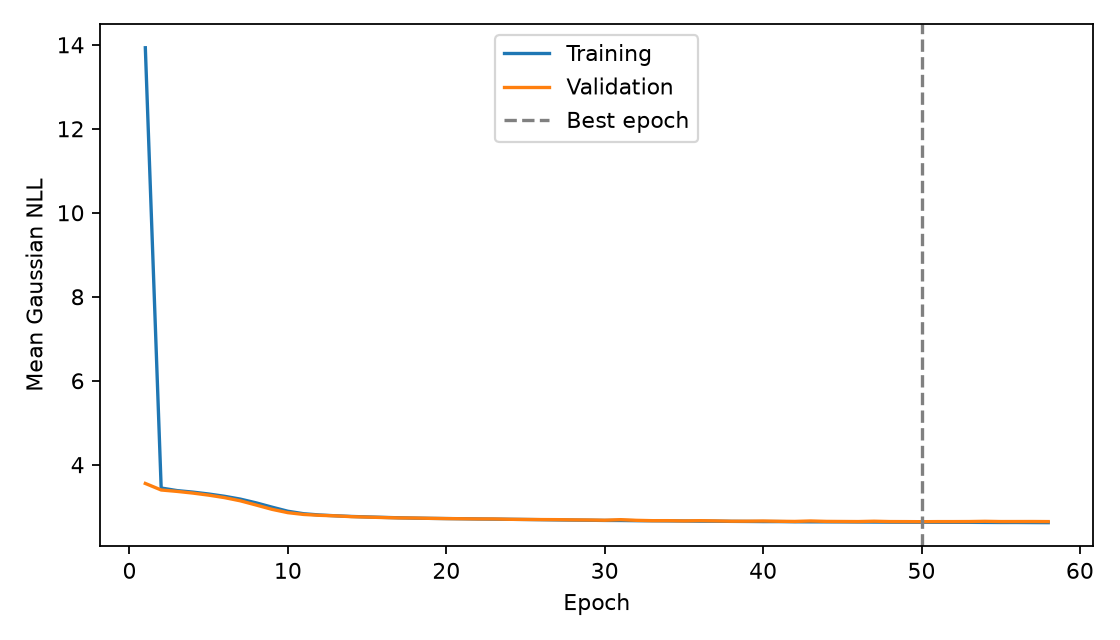

In [11]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(train_losses) + 1), train_losses, label="Training")
plt.plot(range(1, len(val_losses) + 1), val_losses, label="Validation")
plt.axvline(best_epoch, color="gray", linestyle="--", label="Best epoch")
plt.xlabel("Epoch")
plt.ylabel("Mean Gaussian NLL")
plt.legend()
plt.tight_layout()
plt.savefig("training.png", dpi=160)
plt.close()


from IPython.display import Image, display
display(Image(filename="training.png"))


## (d) Probability of a trip taking less than 45 minutes

For a new input $x$, standardizing the fitted Gaussian gives

$$P(Y<45\mid X=x)=\Phi\left(\frac{45-f_\mu(x)}{f_\sigma(x)}\right),$$

where $\Phi$ is the standard normal CDF. Thus, the prediction uses both the estimated mean and standard deviation.


## (e) Test-set evaluation

Define $z_i=\mathbf{1}\{y_i<45\}$ and $p_i=\Phi((45-\mu_i)/\sigma_i)$. I report the Brier score, a proper scoring rule, and accuracy using a 0.5 probability threshold:

$$\mathrm{Brier}=\frac1m\sum_{i=1}^m(p_i-z_i)^2,$$

$$\mathrm{Accuracy}=\frac1m\sum_{i=1}^m\mathbf{1}\{\mathbf{1}(p_i\ge0.5)=z_i\}.$$

For duration prediction, I also report MSE and mean Gaussian NLL. Lower MSE, NLL, and Brier scores are better; higher accuracy is better.


### Held-out test evaluation

In [12]:
with torch.no_grad():
    mean_test, sd_test = model(torch.tensor(x_test))
mean_test = mean_test.numpy()
sd_test = sd_test.numpy()

z_test = (y_test < 45).astype(int)


def evaluate(name, mean, sd):
    p = norm.cdf((45 - mean) / sd)
    nll = 0.5 * np.log(2 * np.pi) + np.log(sd)
    nll = np.mean(nll + 0.5 * ((y_test - mean) / sd) ** 2)
    return {
        "Model": name,
        "MSE": mean_squared_error(y_test, mean),
        "NLL": nll,
        "Brier": brier_score_loss(z_test, p),
        "Accuracy": accuracy_score(z_test, (p >= 0.5).astype(int)),
    }


results = pd.DataFrame([
    evaluate("Constant", np.full(len(y_test), mean), np.full(len(y_test), sd)),
    evaluate("Linear", linear.predict(x_test), np.full(len(y_test), sd_linear)),
    evaluate("MLP", mean_test, sd_test),
])
print(results.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
print("Fraction of test trips under 45 minutes:", round(float(z_test.mean()), 6))
print("Number of test trips at least 45 minutes:", int((z_test == 0).sum()))



   Model       MSE      NLL    Brier  Accuracy
Constant 60.169377 3.467520 0.004457  0.995543
  Linear 56.918900 3.439752 0.004455  0.995543
     MLP 16.437580 2.746337 0.003034  0.996384
Fraction of test trips under 45 minutes: 0.995543
Number of test trips at least 45 minutes: 350


### Save results

In [13]:
results.to_csv("results.csv", index=False)
pd.DataFrame({"train_nll": train_losses, "val_nll": val_losses}).to_csv(
    "history.csv", index=False
)
torch.save(model.state_dict(), "model.pt")


| Model | Test MSE (min²) | Test NLL | Brier score | Accuracy |
|---|---:|---:|---:|---:|
| Constant | 60.169377 | 3.467520 | 0.004457 | 0.995543 |
| Linear | 56.918900 | 3.439752 | 0.004455 | 0.995543 |
| MLP | 16.165384 | 2.770624 | 0.002945 | 0.996447 |

The MLP has test Brier score **0.002945** and accuracy **99.6447%**. In the test set, **99.5543%** of trips take less than 45 minutes; only **350** trips take at least 45 minutes. Therefore, always predicting “under 45 minutes” already achieves very high accuracy. Accuracy alone is insufficient to assess the probability predictions; the Brier score provides an additional evaluation. The Gaussian assumption is the approximation specified in the question, rather than a guarantee that the conditional trip-duration distribution is exactly normal.

The MLP improves on both baselines in test MSE.
The MLP improves on both baselines in test NLL.
The MLP improves on both baselines in test Brier.